In [1]:
import sys

print("Python sürümü:", sys.version.split()[0])
print("Python yolu:", sys.executable)

Python sürümü: 3.12.0
Python yolu: C:\Users\HP\Desktop\SEN421-VM-vs-Docker\.venv\Scripts\python.exe


In [2]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

RESULTS_DIR = PROJECT_ROOT / "results" / "experiments"

records = []

for environment in ["docker", "vm"]:
    for load in ["low", "high"]:
        for run in [1, 2, 3]:

            file_path = (
                RESULTS_DIR
                / environment
                / f"{environment}_{load}_run{run}_stats.csv"
            )

            df = pd.read_csv(file_path)

            aggregated = df[df["Name"] == "Aggregated"].iloc[0]

            records.append({
                "Environment": environment,
                "Load": load,
                "Run": run,
                "Requests": int(aggregated["Request Count"]),
                "Failures": int(aggregated["Failure Count"]),
                "Latency_ms": float(aggregated["Average Response Time"]),
                "RPS": float(aggregated["Requests/s"]),
                "P95_ms": float(aggregated["95%"])
            })

performance_df = pd.DataFrame(records)

display(performance_df)

,Environment,Load,Run,Requests,Failures,Latency_ms,RPS,P95_ms
0,docker,low,1,191,0,4.705183,3.236172,8.0
1,docker,low,2,191,0,4.933658,3.247437,9.0
2,docker,low,3,198,0,4.981816,3.354831,9.0
3,docker,high,1,1139,0,4.813945,19.300390,8.0
4,docker,high,2,1135,0,4.966602,19.217807,8.0
5,docker,high,3,1146,0,5.008021,19.445181,8.0
6,vm,low,1,193,0,8.752599,3.292906,18.0
7,vm,low,2,192,0,8.278211,3.268485,18.0
8,vm,low,3,192,0,8.852589,3.254155,19.0
9,vm,high,1,1140,0,9.318102,19.306383,21.0


In [3]:
summary_df = (
    performance_df
    .groupby(["Environment", "Load"])
    .agg(
        Total_Requests=("Requests", "sum"),
        Total_Failures=("Failures", "sum"),
        Mean_Latency_ms=("Latency_ms", "mean"),
        SD_Latency_ms=("Latency_ms", "std"),
        Mean_RPS=("RPS", "mean"),
        SD_RPS=("RPS", "std"),
        Mean_P95_ms=("P95_ms", "mean"),
        SD_P95_ms=("P95_ms", "std")
    )
    .reset_index()
)

display(summary_df.round(3))

,Environment,Load,Total_Requests,Total_Failures,Mean_Latency_ms,SD_Latency_ms,Mean_RPS,SD_RPS,Mean_P95_ms,SD_P95_ms
0,docker,high,3420,0,4.930,0.102,19.321,0.115,8.000,0.000
1,docker,low,580,0,4.874,0.148,3.279,0.065,8.667,0.577
2,vm,high,3416,0,9.148,0.555,19.299,0.022,20.333,1.155
3,vm,low,577,0,8.628,0.307,3.272,0.020,18.333,0.577


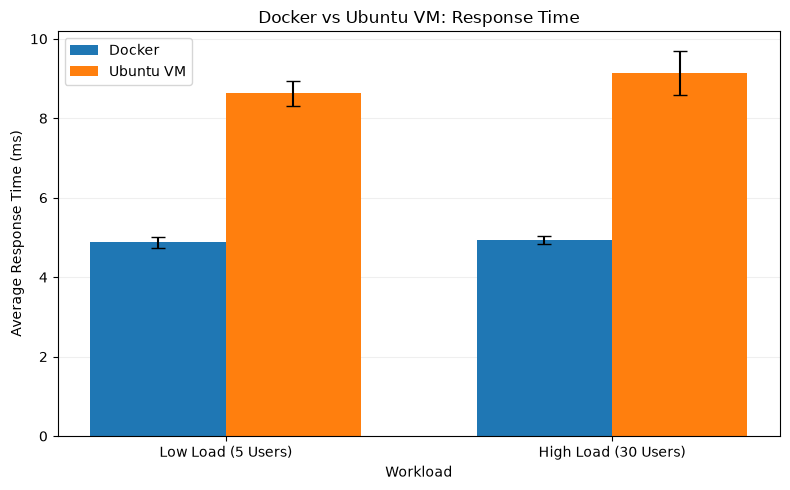

In [4]:
import matplotlib.pyplot as plt
import numpy as np

loads = ["low", "high"]
x = np.arange(len(loads))
width = 0.35

docker = summary_df.set_index(["Environment", "Load"]).loc["docker"]
vm = summary_df.set_index(["Environment", "Load"]).loc["vm"]

docker_means = docker.loc[loads, "Mean_Latency_ms"]
docker_std = docker.loc[loads, "SD_Latency_ms"]

vm_means = vm.loc[loads, "Mean_Latency_ms"]
vm_std = vm.loc[loads, "SD_Latency_ms"]

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    x - width / 2,
    docker_means,
    width,
    yerr=docker_std,
    capsize=5,
    label="Docker"
)

ax.bar(
    x + width / 2,
    vm_means,
    width,
    yerr=vm_std,
    capsize=5,
    label="Ubuntu VM"
)

ax.set_xlabel("Workload")
ax.set_ylabel("Average Response Time (ms)")
ax.set_title("Docker vs Ubuntu VM: Response Time")
ax.set_xticks(x)
ax.set_xticklabels(["Low Load (5 Users)", "High Load (30 Users)"])
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [5]:
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

output_path = FIGURES_DIR / "response_time_comparison.png"

fig.savefig(output_path, dpi=300, bbox_inches="tight")

print(f"Saved: {output_path}")
print(f"File size: {output_path.stat().st_size:,} bytes")

Saved: C:\Users\HP\Desktop\SEN421-VM-vs-Docker\results\figures\response_time_comparison.png
File size: 82,731 bytes


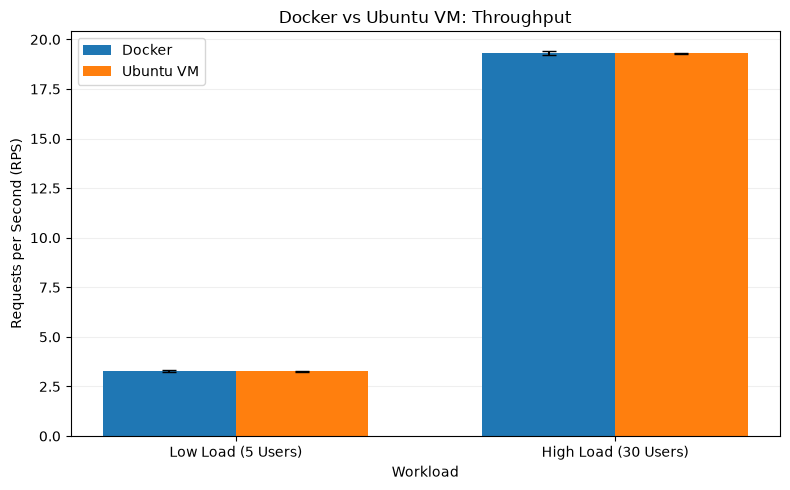

In [6]:
docker_rps = docker.loc[loads, "Mean_RPS"]
docker_rps_std = docker.loc[loads, "SD_RPS"]

vm_rps = vm.loc[loads, "Mean_RPS"]
vm_rps_std = vm.loc[loads, "SD_RPS"]

fig_rps, ax_rps = plt.subplots(figsize=(8, 5))

ax_rps.bar(
    x - width / 2,
    docker_rps,
    width,
    yerr=docker_rps_std,
    capsize=5,
    label="Docker"
)

ax_rps.bar(
    x + width / 2,
    vm_rps,
    width,
    yerr=vm_rps_std,
    capsize=5,
    label="Ubuntu VM"
)

ax_rps.set_xlabel("Workload")
ax_rps.set_ylabel("Requests per Second (RPS)")
ax_rps.set_title("Docker vs Ubuntu VM: Throughput")
ax_rps.set_xticks(x)
ax_rps.set_xticklabels(["Low Load (5 Users)", "High Load (30 Users)"])
ax_rps.legend()
ax_rps.grid(axis="y", alpha=0.2)
ax_rps.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [7]:
output_path = FIGURES_DIR / "throughput_comparison.png"

fig_rps.savefig(output_path, dpi=300, bbox_inches="tight")

print(f"Saved: {output_path}")
print(f"File size: {output_path.stat().st_size:,} bytes")

Saved: C:\Users\HP\Desktop\SEN421-VM-vs-Docker\results\figures\throughput_comparison.png
File size: 88,400 bytes


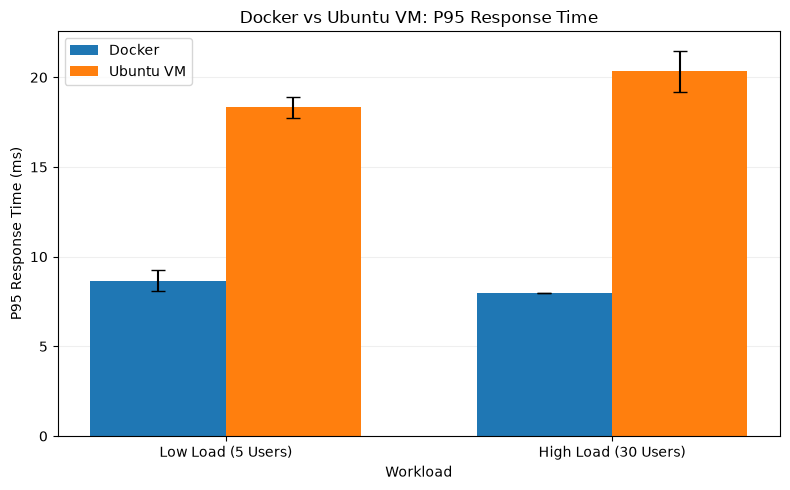

In [8]:
docker_p95 = docker.loc[loads, "Mean_P95_ms"]
docker_p95_std = docker.loc[loads, "SD_P95_ms"]

vm_p95 = vm.loc[loads, "Mean_P95_ms"]
vm_p95_std = vm.loc[loads, "SD_P95_ms"]

fig_p95, ax_p95 = plt.subplots(figsize=(8, 5))

ax_p95.bar(
    x - width / 2,
    docker_p95,
    width,
    yerr=docker_p95_std,
    capsize=5,
    label="Docker"
)

ax_p95.bar(
    x + width / 2,
    vm_p95,
    width,
    yerr=vm_p95_std,
    capsize=5,
    label="Ubuntu VM"
)

ax_p95.set_xlabel("Workload")
ax_p95.set_ylabel("P95 Response Time (ms)")
ax_p95.set_title("Docker vs Ubuntu VM: P95 Response Time")
ax_p95.set_xticks(x)
ax_p95.set_xticklabels(["Low Load (5 Users)", "High Load (30 Users)"])
ax_p95.legend()
ax_p95.grid(axis="y", alpha=0.2)
ax_p95.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [9]:
output_path = FIGURES_DIR / "p95_response_time_comparison.png"

fig_p95.savefig(output_path, dpi=300, bbox_inches="tight")

print(f"Saved: {output_path}")
print(f"File size: {output_path.stat().st_size:,} bytes")

Saved: C:\Users\HP\Desktop\SEN421-VM-vs-Docker\results\figures\p95_response_time_comparison.png
File size: 80,227 bytes


In [10]:
docker_resource_path = (
    PROJECT_ROOT
    / "results"
    / "resources"
    / "docker"
    / "docker_high_run1_resources.csv"
)

vm_resource_path = (
    PROJECT_ROOT
    / "results"
    / "resources"
    / "vm"
    / "vm_high_run1_resources.csv"
)

docker_resources = pd.read_csv(docker_resource_path, nrows=3)
vm_resources = pd.read_csv(vm_resource_path, nrows=3)

print("DOCKER RESOURCE DATA")
display(docker_resources)

print("VM RESOURCE DATA")
display(vm_resources)

DOCKER RESOURCE DATA


,timestamp,elapsed_seconds,cpu_percent,memory_usage,memory_percent
0,2026-10-17T22:17:28.6204450+03:00,"1,07",0.58,37.33MiB / 2GiB,1.82
1,2026-10-17T22:17:31.6951331+03:00,"4,15",2.46,37.32MiB / 2GiB,1.82
2,2026-10-17T22:17:34.7535305+03:00,"7,2",4.57,37.57MiB / 2GiB,1.83


VM RESOURCE DATA


,timestamp,elapsed_seconds,vm_cpu_percent,vm_used_memory_mib,vm_available_memory_mib,fastapi_rss_mib
0,2026-10-17T22:42:11.4312276+03:00,"1,42",1,"386,8","1580,91","48,4"
1,2026-10-17T22:42:14.8203482+03:00,"4,81",7,"368,95","1598,77","48,41"
2,2026-10-17T22:42:18.2227842+03:00,"8,21",9,"367,38","1600,33","48,42"


In [11]:
resource_records = []

for environment in ["docker", "vm"]:
    for run in [1, 2, 3]:
        file_path = (
            PROJECT_ROOT
            / "results"
            / "resources"
            / environment
            / f"{environment}_high_run{run}_resources.csv"
        )

        df = pd.read_csv(file_path)

        if environment == "docker":
            cpu = pd.to_numeric(df["cpu_percent"], errors="raise")
            memory = (
                df["memory_usage"]
                .str.extract(r"([\d.]+)MiB")[0]
                .astype(float)
            )
            fastapi_rss = None
        else:
            cpu = pd.to_numeric(df["vm_cpu_percent"], errors="raise")
            memory = pd.to_numeric(
                df["vm_used_memory_mib"].astype(str).str.replace(",", "."),
                errors="raise"
            )
            fastapi_rss = pd.to_numeric(
                df["fastapi_rss_mib"].astype(str).str.replace(",", "."),
                errors="raise"
            ).mean()

        resource_records.append({
            "Environment": environment,
            "Run": run,
            "Samples": len(df),
            "Mean_CPU_percent": cpu.mean(),
            "Max_CPU_percent": cpu.max(),
            "Mean_RAM_MiB": memory.mean(),
            "Max_RAM_MiB": memory.max(),
            "Mean_FastAPI_RSS_MiB": fastapi_rss
        })

resource_df = pd.DataFrame(resource_records)

display(resource_df.round(3))

,Environment,Run,Samples,Mean_CPU_percent,Max_CPU_percent,Mean_RAM_MiB,Max_RAM_MiB,Mean_FastAPI_RSS_MiB
0,docker,1,19,4.629,7.21,37.878,38.41,NaN
1,docker,2,19,4.304,5.96,38.152,38.59,NaN
2,docker,3,19,4.499,6.58,37.833,38.21,NaN
3,vm,1,18,7.111,10.00,354.860,386.80,48.411
4,vm,2,18,7.056,11.00,354.551,371.81,48.412
5,vm,3,18,6.611,9.00,351.589,372.59,48.431


In [12]:
resource_summary_df = (
    resource_df
    .groupby("Environment")
    .agg(
        Runs=("Run", "count"),
        Mean_CPU_percent=("Mean_CPU_percent", "mean"),
        SD_CPU_percent=("Mean_CPU_percent", "std"),
        Mean_RAM_MiB=("Mean_RAM_MiB", "mean"),
        SD_RAM_MiB=("Mean_RAM_MiB", "std"),
        Mean_FastAPI_RSS_MiB=("Mean_FastAPI_RSS_MiB", "mean"),
        SD_FastAPI_RSS_MiB=("Mean_FastAPI_RSS_MiB", "std")
    )
    .reset_index()
)

display(resource_summary_df.round(3))

,Environment,Runs,Mean_CPU_percent,SD_CPU_percent,Mean_RAM_MiB,SD_RAM_MiB,Mean_FastAPI_RSS_MiB,SD_FastAPI_RSS_MiB
0,docker,3,4.477,0.164,37.954,0.173,NaN,NaN
1,vm,3,6.926,0.274,353.666,1.806,48.418,0.011


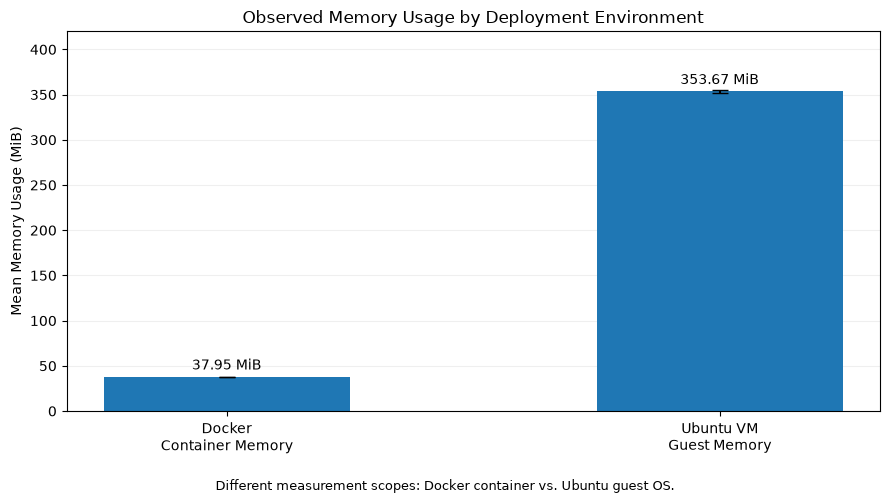

In [13]:
fig_ram, ax_ram = plt.subplots(figsize=(9, 5))

labels = [
    "Docker\nContainer Memory",
    "Ubuntu VM\nGuest Memory"
]

ram_means = resource_summary_df["Mean_RAM_MiB"]
ram_stds = resource_summary_df["SD_RAM_MiB"]

bars = ax_ram.bar(
    labels,
    ram_means,
    yerr=ram_stds,
    capsize=6,
    width=0.5
)

ax_ram.set_ylabel("Mean Memory Usage (MiB)")
ax_ram.set_title("Observed Memory Usage by Deployment Environment")
ax_ram.grid(axis="y", alpha=0.2)
ax_ram.set_axisbelow(True)

for bar, value in zip(bars, ram_means):
    ax_ram.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 8,
        f"{value:.2f} MiB",
        ha="center"
    )

ax_ram.set_ylim(0, 420)

fig_ram.text(
    0.5,
    0.01,
    "Different measurement scopes: Docker container vs. Ubuntu guest OS.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

In [14]:
output_path = FIGURES_DIR / "memory_usage_comparison.png"

fig_ram.savefig(output_path, dpi=300, bbox_inches="tight")

print(f"Saved: {output_path}")
print(f"File size: {output_path.stat().st_size:,} bytes")

Saved: C:\Users\HP\Desktop\SEN421-VM-vs-Docker\results\figures\memory_usage_comparison.png
File size: 110,410 bytes


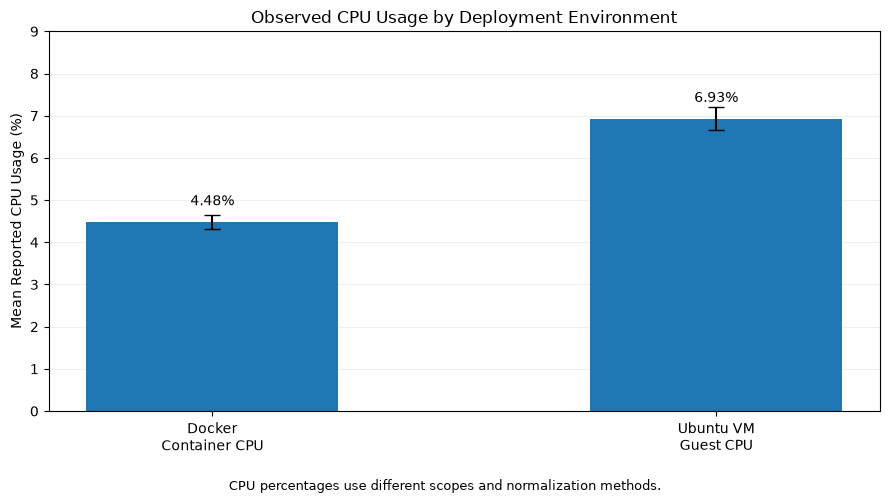

In [15]:
fig_cpu, ax_cpu = plt.subplots(figsize=(9, 5))

labels = [
    "Docker\nContainer CPU",
    "Ubuntu VM\nGuest CPU"
]

cpu_means = resource_summary_df["Mean_CPU_percent"]
cpu_stds = resource_summary_df["SD_CPU_percent"]

bars = ax_cpu.bar(
    labels,
    cpu_means,
    yerr=cpu_stds,
    capsize=6,
    width=0.5
)

ax_cpu.set_ylabel("Mean Reported CPU Usage (%)")
ax_cpu.set_title("Observed CPU Usage by Deployment Environment")
ax_cpu.set_ylim(0, 9)
ax_cpu.grid(axis="y", alpha=0.2)
ax_cpu.set_axisbelow(True)

for bar, value in zip(bars, cpu_means):
    ax_cpu.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.4,
        f"{value:.2f}%",
        ha="center"
    )

fig_cpu.text(
    0.5,
    0.01,
    "CPU percentages use different scopes and normalization methods.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

In [16]:
output_path = FIGURES_DIR / "cpu_usage_comparison.png"

fig_cpu.savefig(output_path, dpi=300, bbox_inches="tight")

print(f"Saved: {output_path}")
print(f"File size: {output_path.stat().st_size:,} bytes")

Saved: C:\Users\HP\Desktop\SEN421-VM-vs-Docker\results\figures\cpu_usage_comparison.png
File size: 101,906 bytes


In [17]:
startup_path = PROJECT_ROOT / "results" / "startup_measurements.csv"

startup_df = pd.read_csv(startup_path)

startup_summary_df = (
    startup_df
    .groupby("Environment")
    .agg(
        Runs=("StartupSeconds", "count"),
        Mean_Startup_s=("StartupSeconds", "mean"),
        SD_Startup_s=("StartupSeconds", "std"),
        Min_Startup_s=("StartupSeconds", "min"),
        Max_Startup_s=("StartupSeconds", "max")
    )
    .reset_index()
)

print("STARTUP MEASUREMENTS")
display(startup_df)

print("STARTUP SUMMARY")
display(startup_summary_df.round(3))

STARTUP MEASUREMENTS


,Environment,Run,StartupSeconds
0,docker,1,1.032
1,docker,2,0.742
2,docker,3,0.697
3,vm,1,38.406
4,vm,2,39.147
5,vm,3,40.153


STARTUP SUMMARY


,Environment,Runs,Mean_Startup_s,SD_Startup_s,Min_Startup_s,Max_Startup_s
0,docker,3,0.824,0.182,0.697,1.032
1,vm,3,39.235,0.877,38.406,40.153


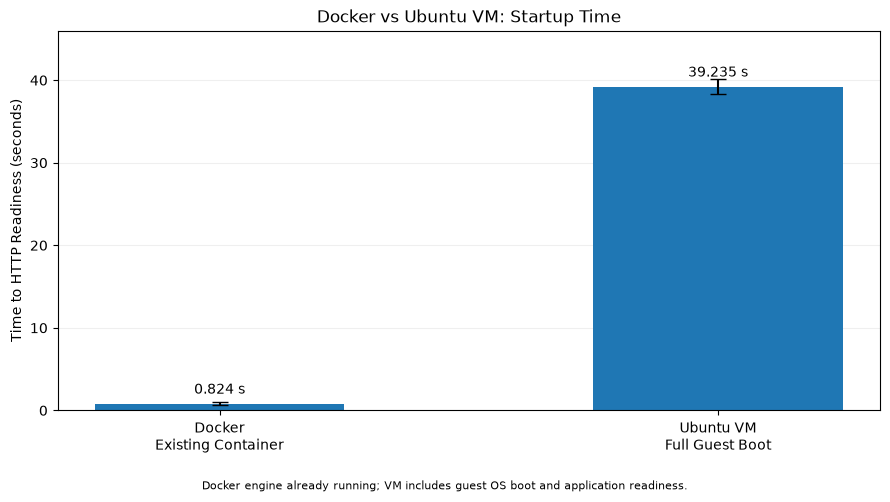

In [18]:
fig_startup, ax_startup = plt.subplots(figsize=(9, 5))

startup_labels = [
    "Docker\nExisting Container",
    "Ubuntu VM\nFull Guest Boot"
]

startup_means = startup_summary_df["Mean_Startup_s"]
startup_stds = startup_summary_df["SD_Startup_s"]

bars = ax_startup.bar(
    startup_labels,
    startup_means,
    yerr=startup_stds,
    capsize=6,
    width=0.5
)

ax_startup.set_ylabel("Time to HTTP Readiness (seconds)")
ax_startup.set_title("Docker vs Ubuntu VM: Startup Time")
ax_startup.set_ylim(0, 46)
ax_startup.grid(axis="y", alpha=0.2)
ax_startup.set_axisbelow(True)

for bar, value in zip(bars, startup_means):
    ax_startup.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.2,
        f"{value:.3f} s",
        ha="center"
    )

fig_startup.text(
    0.5,
    0.01,
    "Docker engine already running; VM includes guest OS boot and application readiness.",
    ha="center",
    fontsize=8
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

In [19]:
output_path = FIGURES_DIR / "startup_time_comparison.png"

fig_startup.savefig(output_path, dpi=300, bbox_inches="tight")

print(f"Saved: {output_path}")
print(f"File size: {output_path.stat().st_size:,} bytes")

Saved: C:\Users\HP\Desktop\SEN421-VM-vs-Docker\results\figures\startup_time_comparison.png
File size: 95,862 bytes


In [20]:
SUMMARY_DIR = PROJECT_ROOT / "results" / "summaries"
SUMMARY_DIR.mkdir(parents=True, exist_ok=True)

summary_files = {
    "performance_summary.csv": summary_df,
    "resource_summary.csv": resource_summary_df,
    "startup_summary.csv": startup_summary_df
}

for filename, dataframe in summary_files.items():
    output_path = SUMMARY_DIR / filename
    dataframe.to_csv(output_path, index=False)

    print(f"Saved: {output_path}")
    print(f"Rows: {len(dataframe)}")

Saved: C:\Users\HP\Desktop\SEN421-VM-vs-Docker\results\summaries\performance_summary.csv
Rows: 4
Saved: C:\Users\HP\Desktop\SEN421-VM-vs-Docker\results\summaries\resource_summary.csv
Rows: 2
Saved: C:\Users\HP\Desktop\SEN421-VM-vs-Docker\results\summaries\startup_summary.csv
Rows: 2
